# PathSnap — Candidate generation, feature engineering and feature selection

Input: the cleaned trips from `data_cleaning.ipynb` (`data_clean/`). This notebook does three things:

1. **Candidate generation:** for every GPS fix, list the road arcs it could plausibly be on.
2. **Feature engineering:** for every (fix, candidate arc) pair, compute features F1–F14 (briefing Section 15).
   Each pair is one row, labelled 1 if the candidate is the fix's true arc and 0 otherwise.
3. **Feature selection:** measure which features actually help, using cross-validation grouped by trip:
   correlation check, permutation importance and group ablation.

**Why candidates instead of predicting the arc number directly?** Arc numbers restart in every trip (each trip has its
own map), so a model cannot learn "arc 1234". Instead it learns to **score** each nearby candidate using features that
mean the same thing everywhere (distance, direction, …). The highest-scoring candidate is the prediction.

## 0. Setup

In [1]:
import glob, json, os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import GroupKFold

DATA_DIR = "../Student folder"   # raw data (needed only for node coordinates)
CLEAN_DIR = "../data_clean"      # output of data_cleaning.ipynb
FEAT_DIR = "../data_features"    # output of this notebook
os.makedirs(FEAT_DIR, exist_ok=True)

R_CAND = 50.0      # candidate search radius (m): the true arc is missing for only ~1.3% of fixes at 50 m
K_MIN = 5          # top up to at least 5 candidates, so no fix is left without any
SAMPLE_STEP = 10.0 # spacing (m) of sample points along arcs, used to find nearby arcs quickly
R_EARTH = 6371008.8
SEED = 42
rng = np.random.default_rng(SEED)

## 1. Helpers

`project` and `point_segment_distance` are the same as in the cleaning notebook. `angle_diff` gives the smallest
angle between two compass directions (0–180°).

In [2]:
def project(lon, lat, lon0, lat0):
    x = np.radians(lon - lon0) * R_EARTH * np.cos(np.radians(lat0))
    y = np.radians(lat - lat0) * R_EARTH
    return x, y


def point_segment_distance(px, py, ax, ay, bx, by):
    dx, dy = bx - ax, by - ay
    L2 = dx * dx + dy * dy
    t = np.where(L2 > 0, ((px - ax) * dx + (py - ay) * dy) / np.where(L2 > 0, L2, 1), 0.0)
    t = np.clip(t, 0, 1)
    return np.hypot(px - (ax + t * dx), py - (ay + t * dy)), t


def angle_diff(a, b):
    d = np.abs(a - b) % 360
    return np.minimum(d, 360 - d)

## 2. Candidate generation

Checking every fix against every arc would be far too slow (up to 19 k fixes × 307 k arcs). Instead:

1. Keep only arcs that are `candidate_eligible` (cleaning step C9) and lie near the trip.
2. Place sample points every 10 m along each arc and put them in a **KD-tree**, a spatial index that answers
   "which points are within r metres?" very quickly.
3. For each fix, query the tree with radius `R_CAND + 5 m`, collect the arcs those samples belong to, then compute
   the exact point-to-arc distance and keep arcs within `R_CAND`.
4. If a fix has fewer than `K_MIN` candidates, top it up with the next-nearest arcs (searching up to 300 m).

In [3]:
def generate_candidates(fx, nx, ny, arcs_df):
    """Returns arrays (fix_index, arc_id, distance, t_along) for all candidate pairs of one trip."""
    gx, gy = fx.x.values, fx.y.values
    fr, to = arcs_df["from"].values, arcs_df["to"].values
    pad = 350
    near = (arcs_df.candidate_eligible.values &
            (np.maximum(nx[fr], nx[to]) > gx.min() - pad) & (np.minimum(nx[fr], nx[to]) < gx.max() + pad) &
            (np.maximum(ny[fr], ny[to]) > gy.min() - pad) & (np.minimum(ny[fr], ny[to]) < gy.max() + pad))
    ids = np.flatnonzero(near)
    nseg = np.maximum(1, np.ceil(arcs_df.length_m.values[ids] / SAMPLE_STEP).astype(int))
    owner = np.repeat(ids, nseg + 1)                                   # arc id of every sample point
    frac = np.concatenate([np.linspace(0, 1, k + 1) for k in nseg])
    sx = nx[fr[owner]] + frac * (nx[to[owner]] - nx[fr[owner]])
    sy = ny[fr[owner]] + frac * (ny[to[owner]] - ny[fr[owner]])
    tree = cKDTree(np.c_[sx, sy])

    def pairs_within(fix_idx, radius):
        hits = tree.query_ball_point(np.c_[gx[fix_idx], gy[fix_idx]], r=radius + SAMPLE_STEP / 2)
        lens = np.fromiter((len(h) for h in hits), int, len(hits))
        fi = np.repeat(fix_idx, lens)
        ai = owner[np.concatenate(hits).astype(int)] if lens.sum() else np.array([], int)
        key = np.unique(fi.astype(np.int64) * len(arcs_df) + ai)       # unique (fix, arc) pairs
        fi, ai = key // len(arcs_df), key % len(arcs_df)
        d, t = point_segment_distance(gx[fi], gy[fi], nx[fr[ai]], ny[fr[ai]], nx[to[ai]], ny[to[ai]])
        return fi, ai, d, t

    fi, ai, d, t = pairs_within(np.arange(len(fx)), R_CAND)
    m = d <= R_CAND
    fi, ai, d, t = fi[m], ai[m], d[m], t[m]
    # top-up for fixes with too few candidates
    counts = np.bincount(fi, minlength=len(fx))
    short = np.flatnonzero(counts < K_MIN)
    if len(short):
        f2, a2, d2, t2 = pairs_within(short, 300.0)
        extra = pd.DataFrame({"f": f2, "a": a2, "d": d2, "t": t2}).sort_values(["f", "d"])
        extra = extra.groupby("f").head(K_MIN)
        extra = extra[extra.d > R_CAND]                                # the ones within R are already included
        fi = np.r_[fi, extra.f.values]; ai = np.r_[ai, extra.a.values]
        d = np.r_[d, extra.d.values]; t = np.r_[t, extra.t.values]
    return fi, ai, d, t

## 3. Feature engineering

For every (fix, candidate) pair we compute the features below. Each one was chosen for a reason from the exploration
(see briefing Section 15):

| id | column | meaning |
|---|---|---|
| F1 | `dist` | distance (m) from the fix to the arc's line |
| F2 | `dist_rank` | 1 = nearest candidate of this fix, 2 = second nearest, … |
| F3 | `dist_gap` | this candidate's distance minus the nearest candidate's distance |
| F4 | `heading_diff` | angle between the direction of travel and the arc direction (90 if unknown) |
| F5 | `speed` | speed of the fix (m/s) |
| F6 | `moving` | 1 if the vehicle is moving (heading known and not standing still) |
| F7 | `dt` | seconds since the previous fix |
| F8 | `along_t` | where the fix projects onto the arc (0 = start, 1 = end) |
| F9 | `arc_len` | arc length (m) |
| F10 | `has_twin` | 1 if the opposite-direction arc exists (two-way road) |
| F11 | `junction_deg` | number of arcs touching the arc's two end nodes (junction size) |
| F12 | `n_cand20`, `n_cand50` | how many candidates lie within 20 m / 50 m of the fix (ambiguity) |
| F13 | `nbr_dist` | mean distance from the previous and next fix to the same arc |
| F14 | `conn_prev` | how this arc connects to the previous fix's nearest arc: 0 same, 1 directly follows, 2 shares a node, 3 not connected |

F14 is a cheap, local version of "can I drive here from where I just was?". The full road-network distance is
used later, inside the HMM.

In [4]:
FEATURES = ["dist", "dist_rank", "dist_gap", "heading_diff", "speed", "moving", "dt", "along_t", "arc_len",
            "has_twin", "junction_deg", "n_cand20", "n_cand50", "nbr_dist", "conn_prev"]
FAMILIES = {
    "distance (F1-F3)": ["dist", "dist_rank", "dist_gap"],
    "direction (F4-F6)": ["heading_diff", "speed", "moving"],
    "map context (F7-F12)": ["dt", "along_t", "arc_len", "has_twin", "junction_deg", "n_cand20", "n_cand50"],
    "sequence (F13-F14)": ["nbr_dist", "conn_prev"],
}


def trip_features(partition, trip):
    cd = f"{CLEAN_DIR}/{partition}/{trip}"
    fx = pd.read_csv(f"{cd}/fixes.csv.gz")
    arcs_df = pd.read_csv(f"{cd}/arcs.csv.gz")
    proj = json.load(open(f"{cd}/projection.json"))
    nodes = np.loadtxt(f"{DATA_DIR}/{partition}/{trip}/{trip}.nodes", ndmin=2)
    nx, ny = project(nodes[:, 0], nodes[:, 1], proj["lon0"], proj["lat0"])
    fr, to = arcs_df["from"].values, arcs_df["to"].values

    fi, ai, d, t = generate_candidates(fx, nx, ny, arcs_df)
    c = pd.DataFrame({"fix": fi, "arc": ai, "dist": d, "along_t": t})

    # F2, F3: rank and gap within each fix
    c["dist_rank"] = c.groupby("fix").dist.rank(method="first").astype(int)
    c["dist_gap"] = c.dist - c.groupby("fix").dist.transform("min")
    # F12: ambiguity around the fix
    c["n_cand20"] = (c.dist <= 20).groupby(c.fix).transform("sum")
    c["n_cand50"] = (c.dist <= 50).groupby(c.fix).transform("sum")

    # F4-F7: properties of the fix
    f = fx.iloc[c.fix.values]
    moving = f.heading_ok.values & ~f.dwell.values
    hd = angle_diff(f.heading.values, arcs_df.bearing.values[c.arc.values])
    c["heading_diff"] = np.where(moving, hd, 90.0)         # 90 = "no information"
    c["speed"] = np.nan_to_num(np.nanmean(np.c_[f.speed_in.values, f.speed_out.values], axis=1))
    c["moving"] = moving.astype(int)
    c["dt"] = np.nan_to_num(f.dt.values, nan=1.0)

    # F9-F11: properties of the arc
    deg = np.bincount(fr, minlength=len(nodes)) + np.bincount(to, minlength=len(nodes))
    c["arc_len"] = arcs_df.length_m.values[c.arc.values]
    c["has_twin"] = arcs_df.has_twin.values[c.arc.values].astype(int)
    c["junction_deg"] = deg[fr[c.arc.values]] + deg[to[c.arc.values]]

    # F13: do the neighbouring fixes (same segment) also fit this arc?
    seg = fx.segment.values
    n = len(fx)
    prev_i = np.where((c.fix.values > 0) & (seg[np.maximum(c.fix.values - 1, 0)] == seg[c.fix.values]),
                      c.fix.values - 1, c.fix.values)
    next_i = np.where((c.fix.values < n - 1) & (seg[np.minimum(c.fix.values + 1, n - 1)] == seg[c.fix.values]),
                      c.fix.values + 1, c.fix.values)
    a_fr, a_to = fr[c.arc.values], to[c.arc.values]
    dp, _ = point_segment_distance(fx.x.values[prev_i], fx.y.values[prev_i], nx[a_fr], ny[a_fr], nx[a_to], ny[a_to])
    dn, _ = point_segment_distance(fx.x.values[next_i], fx.y.values[next_i], nx[a_fr], ny[a_fr], nx[a_to], ny[a_to])
    c["nbr_dist"] = (dp + dn) / 2

    # F14: connection to the previous fix's nearest candidate (no labels used)
    nearest = c[c.dist_rank == 1].set_index("fix").arc
    prev_best = nearest.reindex(prev_i).values
    has_prev = (prev_i != c.fix.values) & ~pd.isna(prev_best)
    pb = np.where(has_prev, prev_best, 0).astype(int)
    same = c.arc.values == pb
    follows = fr[c.arc.values] == to[pb]
    shares = (fr[c.arc.values] == fr[pb]) | (to[c.arc.values] == to[pb]) | (to[c.arc.values] == fr[pb])
    conn = np.where(same, 0, np.where(follows, 1, np.where(shares, 2, 3)))
    c["conn_prev"] = np.where(has_prev, conn, 1)          # first fix of a segment: treat as "follows"

    # label and bookkeeping
    c["y"] = (c.arc.values == f.label_arc.values).astype(int)
    c["keep_train"] = f.keep_train.values
    c["trip"] = trip
    c["partition"] = partition
    return c, fx

### Try it on one trip

In [5]:
c, fx = trip_features("train", "00000045")
print(f"{len(fx)} fixes -> {len(c)} candidate rows ({len(c) / len(fx):.1f} per fix)")
c.head()

640 fixes -> 4845 candidate rows (7.6 per fix)


,fix,arc,dist,along_t,dist_rank,dist_gap,n_cand20,n_cand50,heading_diff,speed,...,dt,arc_len,has_twin,junction_deg,nbr_dist,conn_prev,y,keep_train,trip,partition
0,0,926,22.450505,0.352284,3,1.748534,0,6,175.64,4.173,...,1.0,197.614,1,10,22.291324,1,0,True,00000045,train
1,0,2050,48.965131,1.000000,5,28.263160,0,6,126.55,4.173,...,1.0,48.530,1,10,49.992872,1,0,True,00000045,train
2,0,2059,22.450505,0.647716,4,1.748534,0,6,4.36,4.173,...,1.0,197.614,1,10,22.291324,1,0,True,00000045,train
3,0,4280,20.701971,1.000000,1,0.000000,0,6,42.86,4.173,...,1.0,33.634,1,6,20.698912,1,0,True,00000045,train
4,0,4281,48.965131,0.000000,6,28.263160,0,6,53.45,4.173,...,1.0,48.530,1,10,49.992872,1,0,True,00000045,train


## 4. Build the feature table for all trips

In [6]:
t0 = time.time()
summary = []
for partition in ["train", "student_test"]:
    os.makedirs(f"{FEAT_DIR}/{partition}", exist_ok=True)
    for cd in sorted(glob.glob(f"{CLEAN_DIR}/{partition}/*")):
        trip = os.path.basename(cd)
        c, fx = trip_features(partition, trip)
        c.to_csv(f"{FEAT_DIR}/{partition}/{trip}.csv.gz", index=False)
        has_true = c.groupby("fix").y.max().reindex(range(len(fx)), fill_value=0)
        summary.append(dict(partition=partition, trip=trip, fixes=len(fx), rows=len(c),
                            cand_per_fix=len(c) / len(fx),
                            miss_rate_kept=1 - has_true[fx.keep_train].mean() if fx.keep_train.any() else np.nan))
summary = pd.DataFrame(summary)
summary.to_csv(f"{FEAT_DIR}/feature_summary.csv", index=False)
print(f"built features for {len(summary)} trips in {time.time() - t0:.0f} s; {summary.rows.sum():,} rows")
summary.groupby("partition")[["fixes", "rows"]].sum()

built features for 90 trips in 164 s; 2,325,213 rows


,fixes,rows
partition,,
student_test,19160,222004
train,208417,2103209


### Candidate miss rate

For cleaned training fixes (`keep_train`), how often is the true arc **not** among the candidates? No model can
get those fixes right, so this is the ceiling on accuracy.

In [7]:
tr = summary[summary.partition == "train"]
w = tr.fixes
print(f"candidates per fix (train): {tr.rows.sum() / tr.fixes.sum():.1f}")
print(f"candidate miss rate on kept train fixes: {np.average(tr.miss_rate_kept.fillna(0), weights=w):.2%}")

candidates per fix (train): 10.1
candidate miss rate on kept train fixes: 0.00%


## 5. Load the training table

In [8]:
def load(partition):
    return pd.concat([pd.read_csv(f) for f in sorted(glob.glob(f"{FEAT_DIR}/{partition}/*.csv.gz"))],
                     ignore_index=True)

train = load("train")
train = train[train.keep_train].reset_index(drop=True)   # only fixes with reliable labels (cleaning steps C4-C8)
train["fix_uid"] = train.trip.astype(str) + "_" + train.fix.astype(str)
print(f"{len(train):,} rows, {train.fix_uid.nunique():,} fixes, positives {train.y.mean():.1%}")
train[FEATURES].describe().T.round(2)

1,801,387 rows, 173,637 fixes, positives 9.6%


,count,mean,std,min,25%,50%,75%,max
dist,1801387.0,31.09,31.38,0.00,11.89,27.12,41.23,305.00
dist_rank,1801387.0,9.80,11.04,1.00,3.00,6.00,13.00,150.00
dist_gap,1801387.0,26.00,31.34,0.00,5.48,21.74,36.17,304.60
heading_diff,1801387.0,88.21,61.19,0.00,25.68,90.00,150.22,180.00
speed,1801387.0,13.49,8.43,0.00,7.69,11.43,16.95,99.90
moving,1801387.0,0.94,0.24,0.00,1.00,1.00,1.00,1.00
dt,1801387.0,3.63,603.55,1.00,1.00,1.00,1.00,153064.00
along_t,1801387.0,0.50,0.45,0.00,0.00,0.50,1.00,1.00
arc_len,1801387.0,88.92,191.59,0.07,15.42,35.95,87.66,4666.16
has_twin,1801387.0,0.76,0.43,0.00,1.00,1.00,1.00,1.00


## 6. Feature selection

### 6a. How we measure: top-1 accuracy with GroupKFold

- **Model used for selection:** a gradient-boosted tree classifier (`HistGradientBoostingClassifier`). It is fast,
  handles features on different scales without preprocessing, and captures non-linear effects. It is a tool for
  measuring feature usefulness here; the formal 5-model comparison comes later.
- **GroupKFold(5) by trip:** the 80 trips are split into 5 folds; we train on 4 and test on the 5th, rotating. A
  trip's fixes never appear in both training and testing (neighbouring fixes are nearly identical, so mixing them
  would inflate scores).
- **Top-1 accuracy:** for each test fix, take the candidate with the highest predicted probability and check whether
  it is the true arc. Fixes whose true arc is not among the candidates count as wrong.
- To keep run time short, each fold trains on a random 40% of its training fixes (all candidates of a chosen fix
  are kept together). Testing always uses all fixes of the held-out trips.

In [9]:
gkf = GroupKFold(n_splits=5)
folds = list(gkf.split(train, groups=train.trip))
fix_codes = train.fix_uid.astype("category").cat.codes.values


def top1(df_idx, proba):
    """Share of fixes whose highest-probability candidate is the true arc."""
    sub = pd.DataFrame({"g": fix_codes[df_idx], "p": proba, "y": train.y.values[df_idx]})
    best = sub.loc[sub.groupby("g").p.idxmax()]
    return best.y.mean()


def make_model():
    return HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, max_leaf_nodes=31,
                                          random_state=SEED)


def subsample(idx, frac=0.4):
    g = np.unique(fix_codes[idx])
    chosen = rng.choice(g, int(len(g) * frac), replace=False)
    return idx[np.isin(fix_codes[idx], chosen)]


def cv_top1(features, return_models=False):
    scores, models = [], []
    for tr_idx, va_idx in folds:
        tr_idx = subsample(tr_idx)
        m = make_model().fit(train.loc[tr_idx, features], train.y.values[tr_idx])
        scores.append(top1(va_idx, m.predict_proba(train.loc[va_idx, features])[:, 1]))
        models.append(m)
    return (np.array(scores), models) if return_models else np.array(scores)


# baseline without any model: pick the nearest candidate (dist_rank == 1)
base = [top1(va, -train.dist_rank.values[va]) for _, va in folds]
print(f"nearest-road baseline: top-1 = {np.mean(base):.2%} (folds: {np.round(base, 4)})")

nearest-road baseline: top-1 = 56.65% (folds: [0.6268 0.5749 0.5526 0.5688 0.5093])


**Why is the no-model baseline only about 57%?** Here we score the **exact directed arc**. On a two-way road the arc
and its twin are at the same distance, so "pick the nearest" chooses the wrong direction about half the time. The
88% in the exploration (briefing Section 13) ignored direction. Anything a model gains above about 57% comes largely
from knowing the direction of travel.

### 6b. Redundancy check: correlation between features

Two features that move together (correlation near ±1) carry the same information. Tree models cope with this, but
linear models (logistic regression) and k-NN become unstable or double-count it. We use **Spearman** correlation,
which also catches non-linear but monotonic relationships.

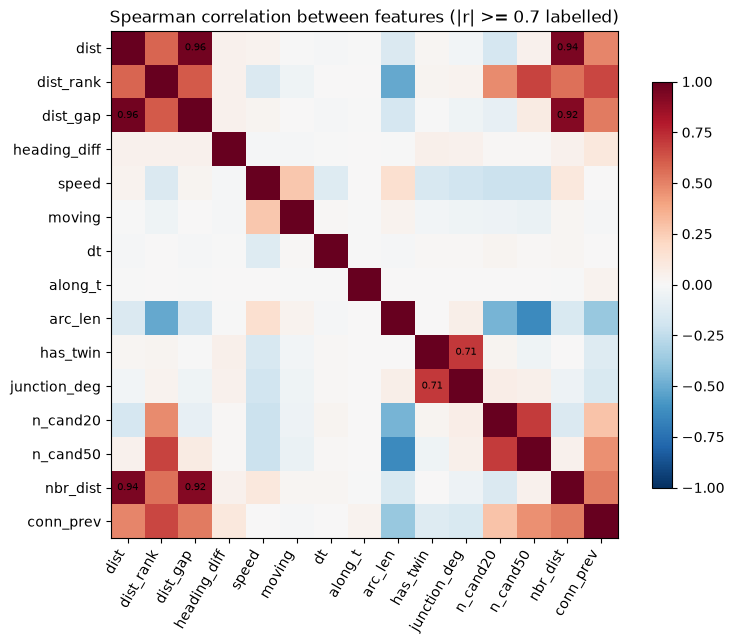

highly correlated pairs: [('dist', 'dist_gap', np.float64(0.961)), ('dist', 'nbr_dist', np.float64(0.939)), ('dist_gap', 'nbr_dist', np.float64(0.92)), ('has_twin', 'junction_deg', np.float64(0.707))]


In [10]:
sample = train.sample(min(300_000, len(train)), random_state=SEED)
corr = sample[FEATURES].corr(method="spearman")
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES))); ax.set_xticklabels(FEATURES, rotation=60, ha="right")
ax.set_yticks(range(len(FEATURES))); ax.set_yticklabels(FEATURES)
for i in range(len(FEATURES)):
    for j in range(len(FEATURES)):
        if i != j and abs(corr.iloc[i, j]) >= 0.7:
            ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im, ax=ax, shrink=0.8); ax.set_title("Spearman correlation between features (|r| >= 0.7 labelled)")
plt.tight_layout(); plt.savefig(f"{FEAT_DIR}/fig_corr.png", dpi=160); plt.show()
pairs = [(a, b, round(corr.loc[a, b], 3)) for i, a in enumerate(FEATURES) for b in FEATURES[i + 1:]
         if abs(corr.loc[a, b]) >= 0.7]
print("highly correlated pairs:", pairs)

### 6c. Full model and permutation importance

**Permutation importance:** after training, we randomly shuffle one feature's column in the test data and measure
how much top-1 accuracy drops. If the model really relies on that feature, scrambling it hurts. If accuracy does not
change, the feature adds nothing. This is measured on held-out trips, so it reflects generalisation, not memorising.

all 15 features: top-1 = 87.34% ± 3.09%


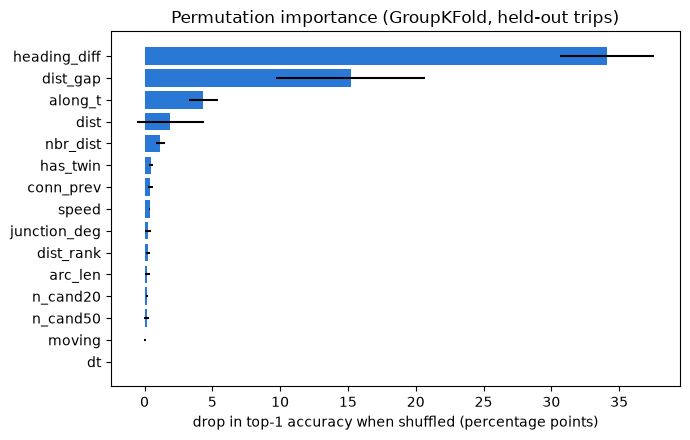

,drop_mean,drop_std
heading_diff,0.3413,0.0345
dist_gap,0.1520,0.0547
along_t,0.0433,0.0108
dist,0.0188,0.0247
nbr_dist,0.0117,0.0034
has_twin,0.0048,0.0013
conn_prev,0.0044,0.0019
speed,0.0039,0.0005
junction_deg,0.0025,0.0024
dist_rank,0.0023,0.0015


In [11]:
full_scores, full_models = cv_top1(FEATURES, return_models=True)
print(f"all {len(FEATURES)} features: top-1 = {full_scores.mean():.2%} ± {full_scores.std():.2%}")

perm = {f: [] for f in FEATURES}
for (tr_idx, va_idx), m, s0 in zip(folds, full_models, full_scores):
    Xva = train.loc[va_idx, FEATURES].copy()
    for f in FEATURES:
        Xp = Xva.copy()
        Xp[f] = rng.permutation(Xp[f].values)
        perm[f].append(s0 - top1(va_idx, m.predict_proba(Xp)[:, 1]))
perm = pd.DataFrame({"drop_mean": {f: np.mean(v) for f, v in perm.items()},
                     "drop_std": {f: np.std(v) for f, v in perm.items()}}).sort_values("drop_mean")
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(perm.index, perm.drop_mean * 100, xerr=perm.drop_std * 100, color="#2a78d6")
ax.set_xlabel("drop in top-1 accuracy when shuffled (percentage points)")
ax.set_title("Permutation importance (GroupKFold, held-out trips)")
plt.tight_layout(); plt.savefig(f"{FEAT_DIR}/fig_perm.png", dpi=160); plt.show()
perm.sort_values("drop_mean", ascending=False).round(4)

### 6d. Group ablation

Remove one **family** of features at a time, retrain and compare. This answers "do we need this kind of
information at all?", which permutation importance can miss when two features in the same family back each other up.

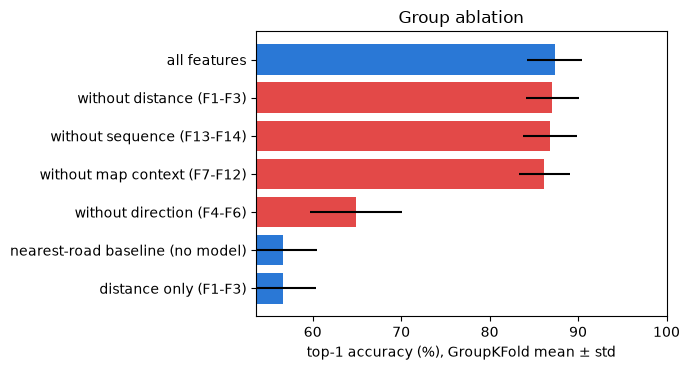

,top1_mean,top1_std,vs_all_pp
distance only (F1-F3),0.5660,0.0377,-30.7434
nearest-road baseline (no model),0.5665,0.0379,-30.6938
without direction (F4-F6),0.6487,0.0520,-22.4717
without map context (F7-F12),0.8621,0.0285,-1.1373
without sequence (F13-F14),0.8682,0.0302,-0.5272
without distance (F1-F3),0.8711,0.0295,-0.2329
all features,0.8734,0.0309,0.0000


In [12]:
ablation = {"all features": full_scores, "distance only (F1-F3)": cv_top1(FAMILIES["distance (F1-F3)"])}
for fam, cols in FAMILIES.items():
    ablation[f"without {fam}"] = cv_top1([f for f in FEATURES if f not in cols])
abl = pd.DataFrame({k: {"top1_mean": v.mean(), "top1_std": v.std()} for k, v in ablation.items()}).T
abl["vs_all_pp"] = (abl.top1_mean - full_scores.mean()) * 100
abl.loc["nearest-road baseline (no model)"] = [np.mean(base), np.std(base), (np.mean(base) - full_scores.mean()) * 100]
abl = abl.sort_values("top1_mean")
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(abl.index, abl.top1_mean * 100, xerr=abl.top1_std * 100,
        color=["#e34948" if "without" in i else "#2a78d6" for i in abl.index])
ax.set_xlim(abl.top1_mean.min() * 100 - 3, 100); ax.set_xlabel("top-1 accuracy (%), GroupKFold mean ± std")
ax.set_title("Group ablation")
plt.tight_layout(); plt.savefig(f"{FEAT_DIR}/fig_ablation.png", dpi=160); plt.show()
abl.round(4)

### 6e. Decision

**Rule:** keep a feature only if shuffling it costs more than **0.05 percentage points** of top-1 accuracy on held-out
trips. Then **confirm** by retraining with the reduced set: accuracy must not fall by more than the fold-to-fold
spread.

The correlation check is used to *explain* results rather than as a hard filter. For example, `dist`, `dist_gap` and
`nbr_dist` are highly correlated, which is why removing the whole distance family costs little: `nbr_dist` still
carries the distance information.

In [13]:
THRESH = 0.0005   # 0.05 percentage points of top-1 accuracy
selected = [f for f in FEATURES if perm.loc[f, "drop_mean"] > THRESH]
dropped = [(f, f"permutation importance {perm.loc[f, 'drop_mean'] * 100:.3f} pp") for f in FEATURES
           if f not in selected]
print("selected:", selected)
print("dropped:", dropped)

sel_scores = cv_top1(selected)
print(f"selected set: top-1 = {sel_scores.mean():.2%} ± {sel_scores.std():.2%} "
      f"(all features {full_scores.mean():.2%} ± {full_scores.std():.2%}, nearest-road baseline {np.mean(base):.2%})")
print("confirmed: no meaningful loss" if full_scores.mean() - sel_scores.mean() <= full_scores.std()
      else "WARNING: reduced set is worse; keep all features")

selected: ['dist', 'dist_rank', 'dist_gap', 'heading_diff', 'speed', 'along_t', 'arc_len', 'has_twin', 'junction_deg', 'n_cand20', 'n_cand50', 'nbr_dist', 'conn_prev']
dropped: [('moving', 'permutation importance 0.023 pp'), ('dt', 'permutation importance 0.009 pp')]


selected set: top-1 = 87.33% ± 3.14% (all features 87.34% ± 3.09%, nearest-road baseline 56.65%)
confirmed: no meaningful loss


**Why the dropped features add nothing, even though they made sense in advance:**
- `moving`: when the car is not moving we already set `heading_diff` to 90 ("no information"), so the model can read
  "not moving" from `heading_diff`. The flag duplicates information in a non-linear way that correlation does not show.
- `dt`: 96.7% of time steps are exactly 1 s, and the long pauses are already cut into separate segments by cleaning
  step C2, so `dt` is almost constant and cannot separate right from wrong candidates.

### 6f. Development check on student_test

Train once on all (cleaned) training fixes with the selected features and score the 10 student_test trips. Top-1 is
reported on (a) fixes with reliable labels (`keep_train`) and (b) all fixes. These numbers are **not** used to make
any choice above; they are only a sanity check that the result generalises.

In [14]:
test = load("student_test")
test["fix_uid"] = test.trip.astype(str) + "_" + test.fix.astype(str)
m = make_model().fit(train[selected], train.y)
test["p"] = m.predict_proba(test[selected])[:, 1]


def top1_df(df, score):
    best = df.loc[df.groupby("fix_uid")[score].idxmax()]
    return best.y.mean()


test["neg_rank"] = -test.dist_rank
res = {
    "model top-1 (reliable-label fixes)": top1_df(test[test.keep_train], "p"),
    "model top-1 (all fixes)": top1_df(test, "p"),
    "nearest-road top-1 (reliable-label fixes)": top1_df(test[test.keep_train], "neg_rank"),
    "nearest-road top-1 (all fixes)": top1_df(test, "neg_rank"),
}
for k, v in res.items():
    print(f"{k}: {v:.2%}")

model top-1 (reliable-label fixes): 89.10%
model top-1 (all fixes): 86.38%
nearest-road top-1 (reliable-label fixes): 55.40%
nearest-road top-1 (all fixes): 54.13%


## 7. Save the results

In [15]:
results = {
    "n_train_rows": int(len(train)), "n_train_fixes": int(train.fix_uid.nunique()),
    "cand_per_fix_train": float(tr.rows.sum() / tr.fixes.sum()),
    "miss_rate_kept_train": float(np.average(tr.miss_rate_kept.fillna(0), weights=w)),
    "baseline_top1": float(np.mean(base)), "full_top1": float(full_scores.mean()), "full_top1_std": float(full_scores.std()),
    "selected": selected, "dropped": dropped, "selected_top1": float(sel_scores.mean()),
    "selected_top1_std": float(sel_scores.std()),
    "perm": perm.drop_mean.to_dict(), "perm_std": perm.drop_std.to_dict(),
    "ablation": abl.top1_mean.to_dict(), "ablation_std": abl.top1_std.to_dict(),
    "corr_pairs": pairs, "student_test": res,
}
json.dump(results, open(f"{FEAT_DIR}/selection_results.json", "w"), indent=1, default=float)
print("saved", f"{FEAT_DIR}/selection_results.json")

saved ../data_features/selection_results.json


## Summary

- Every fix gets a short list of candidate arcs: all eligible arcs within 50 m, topped up to at least 5.
- Each (fix, candidate) row carries features F1–F14 and the label `y`. The tables are in `data_features/<partition>/`.
- Feature selection used GroupKFold by trip on the 80 train trips: correlation, permutation importance and group
  ablation. The selected list is in `selection_results.json`, and the models in the next notebook should use it.
- student_test was only used as a final sanity check, never to choose features.